In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


# Qiskit Superposition 01
Various state can be expressed at the same time by creating superposition.
In terms of n bits binary number, we can easily make n states by operating Hadamard to all the qubits.  

This notebook provides a common routine to create n superpositions for n qubits easily

In [2]:
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit_backend_config import IBMQ, execute, Aer
from qiskit.visualization import plot_histogram
import math

### 2 qubits- 4 states superposition
It is easy, just add a H gate in each qubit, that's it

{'00': 264, '01': 257, '10': 279, '11': 224}


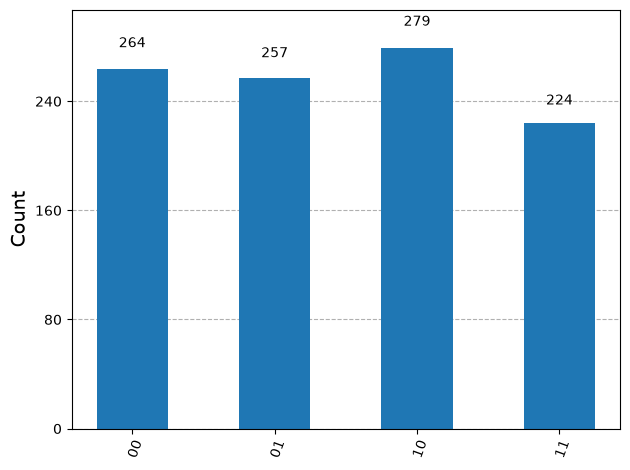

In [3]:
q = QuantumRegister(2, 'q')
c = ClassicalRegister(2, 'c')
qc = QuantumCircuit(q, c)

qc.h(q)

qc.measure(q, c)

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)

So how to generalize?

In [5]:
def power2(q):
    qc.h(q)

Now using this routine create 2^n superpositions on n qubits

{'01000': 34, '11010': 47, '11110': 26, '00100': 33, '00111': 33, '11111': 37, '01010': 30, '00110': 33, '11100': 42, '11001': 27, '01111': 32, '10110': 31, '10010': 35, '10100': 34, '01110': 32, '11011': 21, '01101': 34, '01001': 34, '00101': 39, '00011': 30, '01011': 31, '10001': 31, '00010': 31, '11000': 18, '10111': 30, '00001': 33, '01100': 42, '11101': 38, '00000': 31, '10101': 21, '10000': 26, '10011': 28}


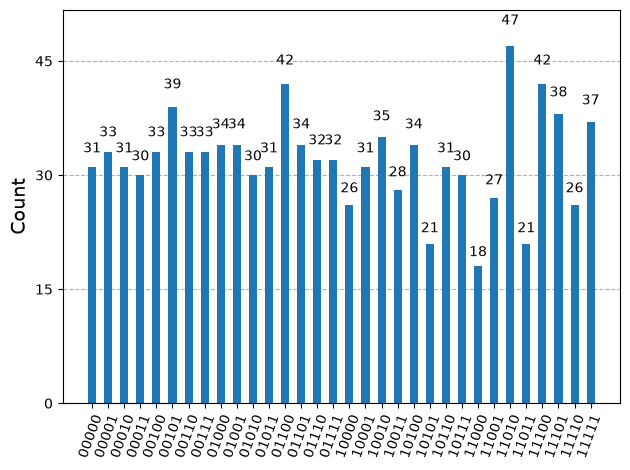

In [7]:
n=5
q = QuantumRegister(n, 'q')
c = ClassicalRegister(n, 'c')
qc = QuantumCircuit(q, c)

power2(q)

qc.measure(q, c)

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)